# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [3]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv(r'C:\Users\Nikhilesh\Desktop\New folder (2)\OneDrive_1_19-11-2026\world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

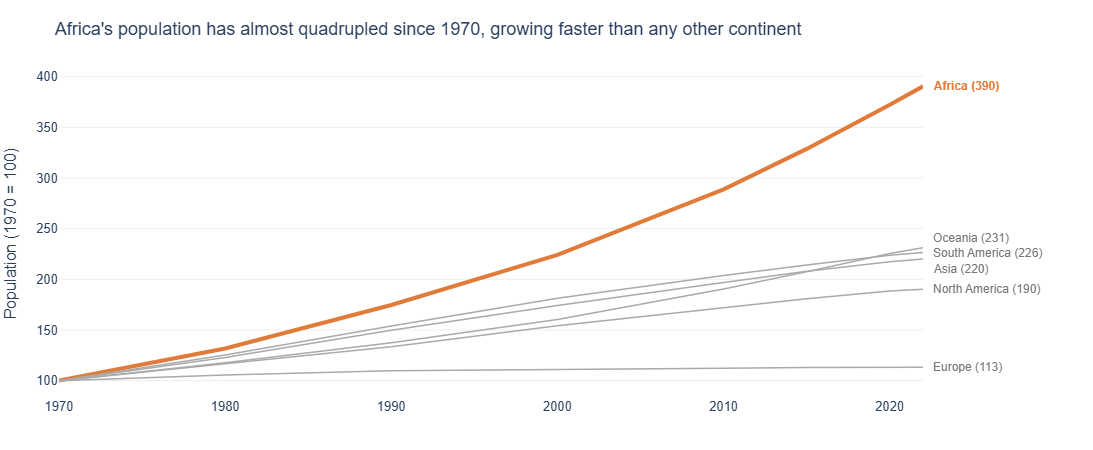

In [6]:
# Q1
cont = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
cont['Index'] = cont['Population'] / cont.groupby('Continent')['Population'].transform('first') * 100

last = cont[cont['Year'] == 2022].sort_values('Index', ascending=False)
fastest = last.iloc[0]['Continent']
color_map = {c: '#E07B39' if c == fastest else '#AAAAAA' for c in cont['Continent'].unique()}

fig = px.line(cont, x='Year', y='Index', color='Continent', color_discrete_map=color_map,
              labels={'Index': 'Population (1970 = 100)', 'Year': ''},
              title="Africa's population has almost quadrupled since 1970, growing faster than any other continent",
              template='plotly_white', height=450, width=950)

fig.update_traces(line=dict(width=1.5), showlegend=False)
fig.update_traces(line=dict(width=4), selector=dict(name=fastest))
fig.update_layout(font=dict(family='Arial', size=13), margin=dict(l=10, r=170, t=70, b=40),
                  xaxis=dict(showgrid=False, range=[1970, 2022]),
                  yaxis=dict(gridcolor='#EEEEEE'))

# direct labels at the end of each line 
for _, r in last.iterrows():
    hl = r['Continent'] == fastest
    fig.add_annotation(x=2022, y=r['Index'], text=f"{r['Continent']} ({r['Index']:.0f})",
                       showarrow=False, xanchor='left', xshift=8,
                       yshift={'Oceania': 10, 'Asia': -10}.get(r['Continent'], 0),
                       font=dict(size=12, family='Arial', color='#E07B39' if hl else '#777777',
                                 weight='bold' if hl else 'normal'))
fig.show()

Africa is Growing the fastest as its population is now almost four times its 1970 size. Oceania, South America and Asia are a little over twice their 1970 size, North America is about 1.9 times, and Europe has grown only slightly (about 13%).

I used a line chart because the question is about how population changes over time. I have set every continent to 100 os that we can the compare the growth and not only size, SInce Asia's huge numbers would hide others. As per question above and chart we can see se that Africa is the fastest growing continent for which I have kept it in orange colour and rest other contents I have kept it thin line grey color so that there is no legend required and chart looks clean.

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

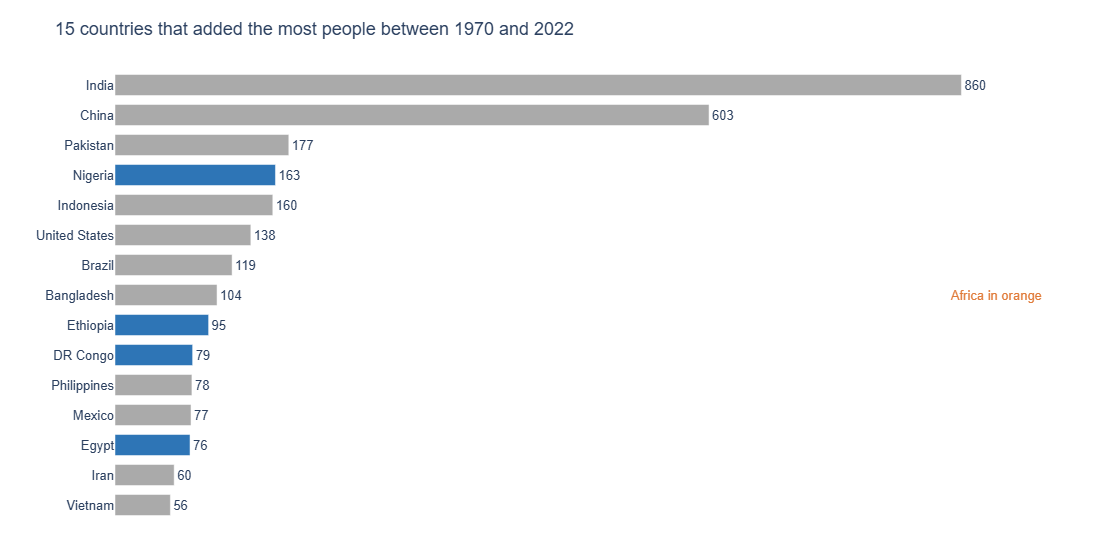

In [10]:
# Q2
df['Added'] = (df['2022 Population'] - df['1970 Population']) / 1e6   # millions
top15 = df.nlargest(15, 'Added').sort_values('Added')
n_africa = (top15['Continent'] == 'Africa').sum()
top15['Group'] = top15['Continent'].apply(lambda c: 'Africa' if c == 'Africa' else 'Other')

fig = px.bar(top15, x='Added', y='Country', orientation='h', color='Group',
             category_orders={'Country': top15['Country'].tolist()[::-1]},   
             color_discrete_map={'Africa': '#2E75B6', 'Other': '#AAAAAA'},
             text=top15['Added'].map('{:,.0f}'.format),
             labels={'Added': 'People added, 1970 to 2022 (millions)', 'Country': ''},
             title=f'15 countries that added the most people between 1970 and 2022',
             template='plotly_white', height=550, width=950)

fig.update_traces(textposition='outside', cliponaxis=False)
fig.update_layout(showlegend=False, font=dict(family='Arial', size=13),
                  xaxis=dict(visible=False, range=[0, top15['Added'].max() * 1.12]),   
                  yaxis=dict(showgrid=False), bargap=0.3,
                  margin=dict(l=10, r=30, t=70, b=30))
fig.add_annotation(x=0.98, y=0.5, xref='paper', yref='paper', showarrow=False,
                   xanchor='right', text='Africa in orange', font=dict(color='#E07B39', size=13))
fig.show()

I used the bar chart because the question is about ranking 15 countries, and bars makes it easy to see ewhich country added the most. The bar starts at zero and the countries are listed from biggest to smallest. Four of the countries that is Nigeria, Ethopia, DR Congo and Egypt in Africa. I have used blue colour for those and for rest I have used grey colour. This way is easier to interpret to answer and at just beside the bars I have put the numbers so that legend is not needed.

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

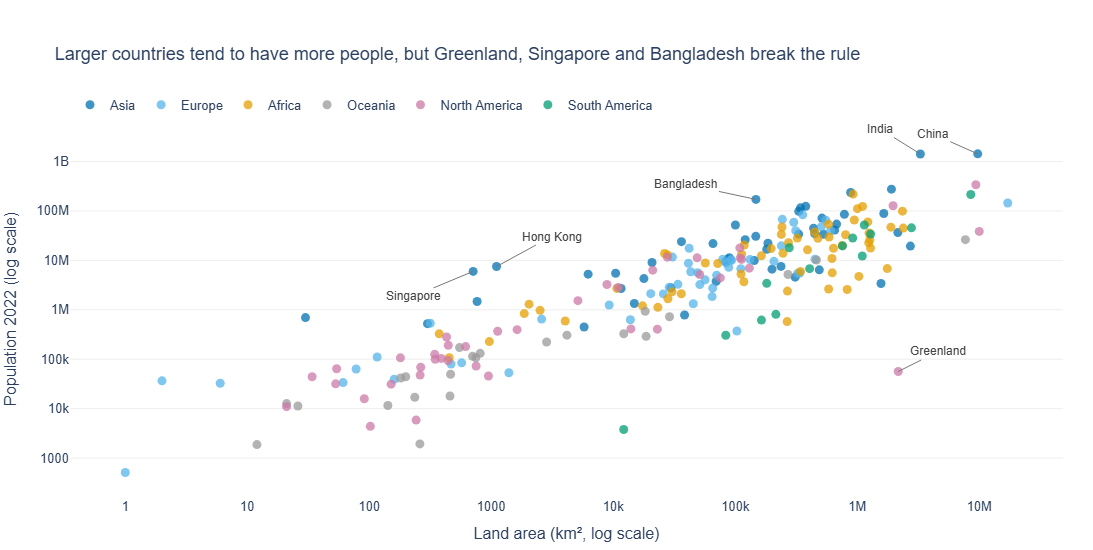

In [12]:
# Q3
import numpy as np

colors = {'Asia': '#0072B2', 'Africa': '#E69F00', 'Europe': '#56B4E9',
          'North America': '#CC79A7', 'South America': '#009E73', 'Oceania': '#999999'}   

fig = px.scatter(df, x='Area', y='2022 Population', color='Continent',
                 color_discrete_map=colors, hover_name='Country', log_x=True, log_y=True,
                 labels={'Area': 'Land area (km², log scale)', '2022 Population': 'Population 2022 (log scale)'},
                 title='Larger countries tend to have more people, but Greenland, Singapore and Bangladesh break the rule',
                 template='plotly_white', height=550, width=1000, opacity=0.75)

fig.update_traces(marker=dict(size=9))
fig.update_layout(font=dict(family='Arial', size=13),
                  legend=dict(orientation='h', x=0, y=1.08, title=''),
                  margin=dict(l=10, r=30, t=120, b=40),
                  xaxis=dict(showgrid=False), yaxis=dict(gridcolor='#EEEEEE'))


notes = {'Greenland': (40, -20), 'Singapore': (-60, 25), 'Hong Kong': (55, -30),
         'Bangladesh': (-70, -15), 'India': (-40, -25), 'China': (-45, -20)}
for name, (ax, ay) in notes.items():
    r = df[df['Country'] == name].iloc[0]
    fig.add_annotation(x=np.log10(r['Area']), y=np.log10(r['2022 Population']), text=name,
                       showarrow=True, arrowhead=0, arrowcolor='#777777', ax=ax, ay=ay,
                       font=dict(size=12, color='#444444', family='Arial'))
fig.show()

Yes, there a relationship between a country's land area and its 2022 population as bigger countries generally have more people and this lies on every continent. As we can see Greenland breaks the pattern with lots of land but with few people. Singapore, Hong Kong and Thailand breaks the other way with more poeple but less land. 

I have used scatter plot because it shows how two numbers, land area nad population move together.Log scales stop the tiny and huge countries from squashing the chart, colour shows the continent, and I only labelled the countries that break the pattern.

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

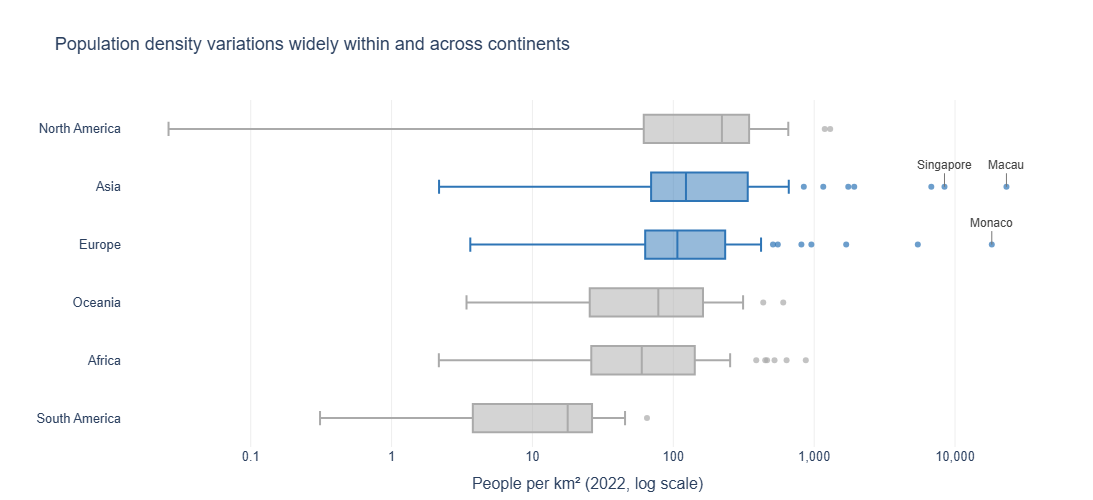

In [14]:
# Q4
df = df.rename(columns={'Density': 'Density'})   
order = df.groupby('Continent')['Density'].median().sort_values(ascending=False).index.tolist()
color_map = {c: '#2E75B6' if c in ('Asia', 'Europe') else '#AAAAAA' for c in order}

fig = px.box(df, x='Density', y='Continent', color='Continent', color_discrete_map=color_map,
             category_orders={'Continent': order}, points='outliers', hover_name='Country', log_x=True,
             labels={'Density': 'People per km² (2022, log scale)', 'Continent': ''},
             title='Population density variations widely within and across continents',
             template='plotly_white', height=500, width=1000)

fig.update_traces(marker=dict(size=6, opacity=0.7))
fig.update_layout(showlegend=False, font=dict(family='Arial', size=13),
                  xaxis=dict(gridcolor='#EEEEEE', tickvals=[0.1, 1, 10, 100, 1000, 10000],
                             ticktext=['0.1', '1', '10', '100', '1,000', '10,000']),
                  yaxis=dict(showgrid=False), margin=dict(l=10, r=40, t=100, b=40))


for name in ['Macau', 'Monaco', 'Singapore']:
    r = df[df['Country'] == name].iloc[0]
    fig.add_annotation(x=np.log10(r['Density']), y=r['Continent'], text=name, showarrow=True,
                       arrowhead=0, arrowcolor='#777777', ax=0, ay=-22,
                       font=dict(size=12, color='#444444', family='Arial'))
fig.show()

Typically population density varies form 18 people per km² in South America to 221 in North America. Every continent has a wide spread, and Asia and Europe have extreme outliers like Macau and Monaco, so the average would be misleading.

I used the box plot because the question asks for the spread, not just the average. THe box plot shows the typical range and outliers for each continent side by side. I used a log scale so that extreme places don't get squashed. I have used blue colour for Asia and Europe because the have the biggest outliers and for rest I have used grey colour.

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

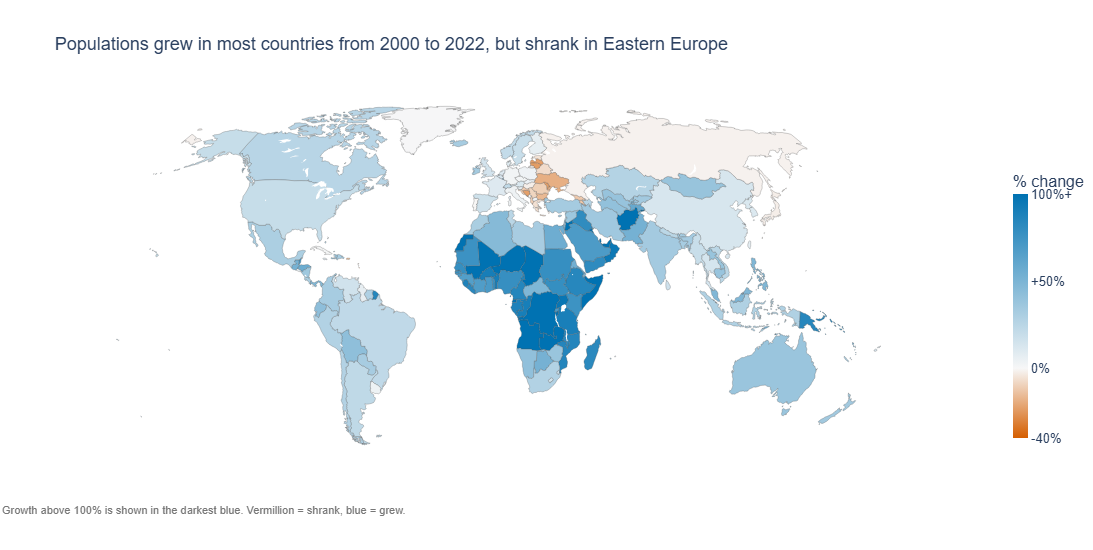

In [16]:
# Q5
df['Change'] = (df['2022 Population'] / df['2000 Population'] - 1) * 100
df['Change_capped'] = df['Change'].clip(upper=100)    
n_shrank = (df['Change'] < 0).sum()
n_total = len(df)


scale = [(0, '#D55E00'), (40/140, '#F7F7F7'), (1, '#0072B2')]   

fig = px.choropleth(df, locations='CCA3', locationmode='ISO-3', color='Change_capped',
                    color_continuous_scale=scale, range_color=[-40, 100],
                    hover_name='Country',
                    hover_data={'CCA3': False, 'Change_capped': False, 'Change': ':.1f'},
                    labels={'Change_capped': '% change', 'Change': '% change 2000 to 2022'},
                    title=f'Populations grew in most countries from 2000 to 2022, but shrank in Eastern Europe',
                    template='plotly_white', height=550, width=1000)

fig.update_traces(marker_line_width=0.3, marker_line_color='#555555')
fig.update_layout(font=dict(family='Arial', size=13), margin=dict(l=0, r=60, t=100, b=40),
                  geo=dict(showframe=False, showcoastlines=False, projection_type='natural earth'),
                  coloraxis_colorbar=dict(title='% change', thickness=15, len=0.7,
                                          tickvals=[-40, 0, 50, 100],
                                          ticktext=['-40%', '0%', '+50%', '100%+']))
fig.add_annotation(x=0, y=-0.02, xref='paper', yref='paper', showarrow=False, xanchor='left',
                   text='Growth above 100% is shown in the darkest blue. Vermillion = shrank, blue = grew.',
                   font=dict(size=11, color='#777777'))
fig.show()

Out of 234 countries, 200 countries population greq where 34 countries population shrank. Africa and other parts of Middle East has the strongest growth in population. The countries that shrank are mostly in Europe, especially in Eastern Europe plus a few islands.

I used the choropleth map because the question asked where countries grew and shrank, so location matters. I used blue colour for the growth and orange colour for shrank and white colour for countries lying between the two as it is easy for colour blinded readers to interpret the chart. I capped the colour scale at +100% so that the extreme countries don't hide in the chart.

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

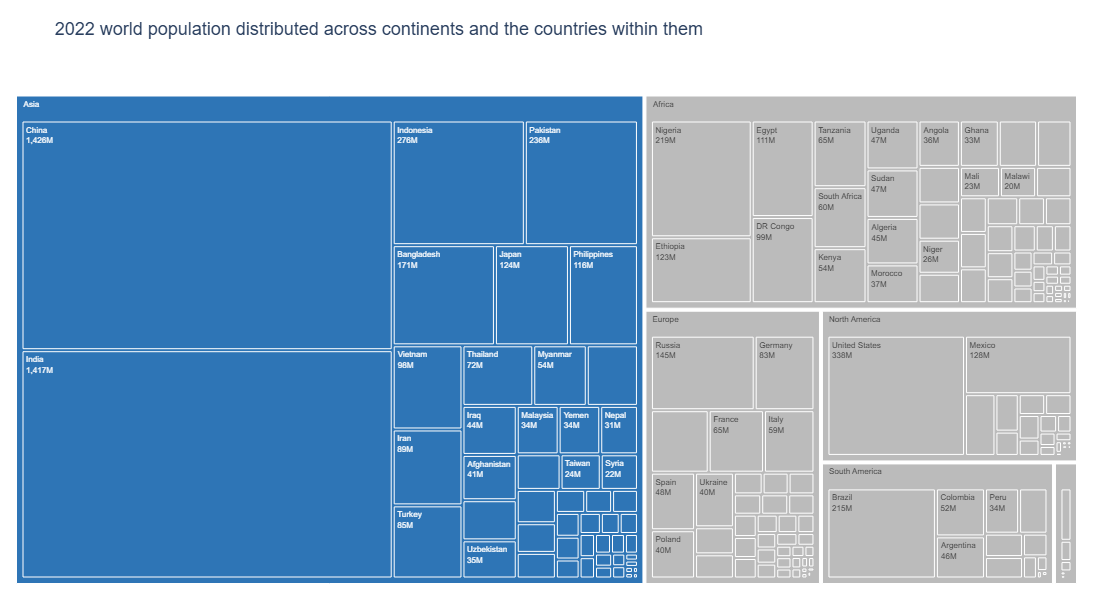

In [18]:
# Q6
df['Group'] = df['Continent'].apply(lambda c: 'Asia' if c == 'Asia' else 'Other')
df['Pop_M'] = df['2022 Population'] / 1e6                      
colors = {'Asia': '#2E75B6', 'Other': '#BBBBBB'}

fig = px.treemap(df, path=['Continent', 'Country'], values='Pop_M', color='Group',
                 color_discrete_map=colors, labels={'Pop_M': 'Population (millions)'},
                 title='2022 world population distributed across continents and the countries within them',
                 template='plotly_white', height=600, width=1000)

fig.update_traces(texttemplate='%{label}<br>%{value:,.0f}M',
                  hovertemplate='<b>%{label}</b><br>%{value:,.0f} million',
                  marker_line_color='white', marker_line_width=1)
fig.update_layout(font=dict(family='Arial', size=13), margin=dict(l=10, r=10, t=70, b=10),
                  uniformtext=dict(minsize=8, mode='hide'))     # hide labels too small to read


fig.data[0].marker.colors = [c if c in colors.values() else '#DDDDDD' for c in fig.data[0].marker.colors]
fig.show()

I used a treemap because the question asks for continents and the countries inside them in one figure, and a treemap shows both levels together, with area showing population. Asia is blue and the rest are grey, so the main finding is clear straight away. I hid the labels on very small countries because they were unreadable, but you can still hover over them to see the numbers.

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

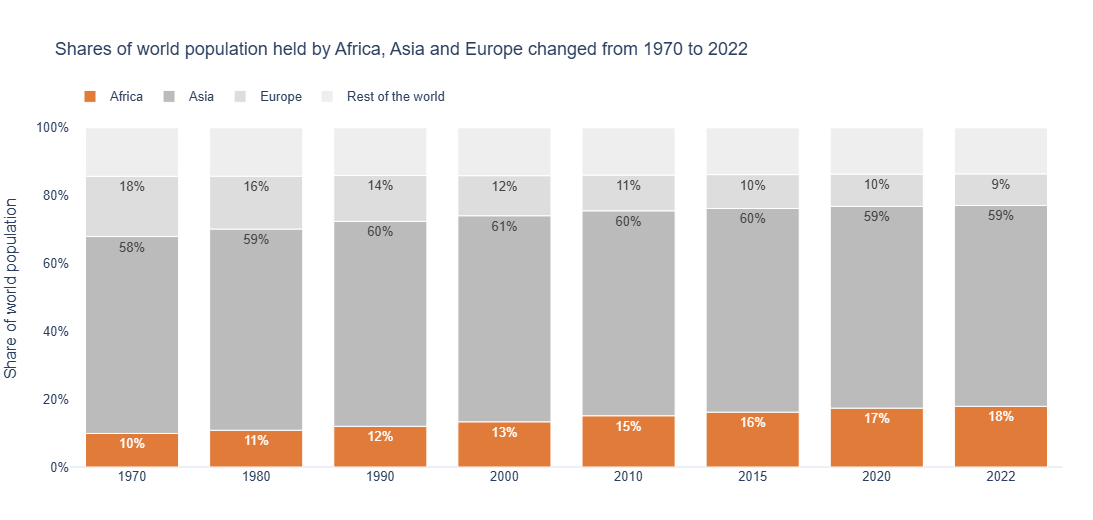

In [21]:
# Q7
df_long['Region'] = df_long['Continent'].where(df_long['Continent'].isin(['Africa', 'Asia', 'Europe']), 'Rest of the world')
share = df_long.groupby(['Year', 'Region'], as_index=False)['Population'].sum()
share['Share'] = share['Population'] / share.groupby('Year')['Population'].transform('sum')   


share['Label'] = np.where(share['Region'].isin(['Africa', 'Asia', 'Europe']), share['Share'].map('{:.0%}'.format), '')

order = ['Africa', 'Asia', 'Europe', 'Rest of the world']      # Africa on the baseline
colors = {'Africa': '#E07B39', 'Asia': '#BBBBBB', 'Europe': '#DDDDDD', 'Rest of the world': '#EEEEEE'}

fig = px.bar(share, x='Year', y='Share', color='Region', text='Label', color_discrete_map=colors,
             category_orders={'Region': order}, labels={'Share': 'Share of world population', 'Year': ''},
             title="Shares of world population held by Africa, Asia and Europe changed from 1970 to 2022",
             template='plotly_white', height=520, width=950)

fig.update_traces(textposition='inside', textfont=dict(color='white', size=13),
                  marker_line_color='white', marker_line_width=1)
fig.update_traces(textfont=dict(color='#444444', size=13), selector=dict(name='Asia'))
fig.update_traces(textfont=dict(color='#444444', size=13), selector=dict(name='Europe'))
fig.update_layout(font=dict(family='Arial', size=13), legend=dict(orientation='h', x=0, y=1.08, title=''),
                  xaxis=dict(type='category'), yaxis=dict(tickformat='.0%', showgrid=False),
                  margin=dict(l=10, r=30, t=110, b=40), bargap=0.25)
fig.show()

Africa's Share of the world population grew about 10% in 1970 to 18% in 2022. Europe's share fell from 18% to 9%. Asia Share stayed high at 59%.

I used 100% stacked bar chart because the question is about eaach continet's share of the world total and how it changes over time. I grouped the other three continents as rest of the world so that it is easy to read the chart as it shows the only four parts. I have used orange colour for Africa so that growth is easy to follow and grey colour for other parts. I put percentages directly on the bars, so no one needs a legend to guess.